# **Projeto Final — Aprendizado de Máquina I (2026.2) · Parte II: aplicação**
### Grupo: *Machine Learning Name in progress*

- Tipo de problema: **Classificação**
- Conjunto de dados: [**30000 Spotify Songs**](https://www.kaggle.com/datasets/joebeachcapital/30000-spotify-songs)
- Objetivo principal: **prever o gênero de uma nova música**


- **Equipe responsável**
    - Ryan Kevin
    - Mateus Bandeira
    - Micaele Brandão
    - Vinicius Flesch
- **Revisão** 
    - Lucas Vieira
    - Mateus Almeida

## 0. Configuração e reprodutibilidade

- Versão da biblioteca: 1.0.0
- Semente global: `67`
- Instalação: `pip install "mlnip-lib @ git+https://github.com/Machine-Learning-Name-in-progress/ML-Library@<hash>"`

### 0.1 Imports

In [78]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# biblioteca
from ml_library.metrics.classification_metrics import (
    accuracy,
    area_under_curve,
    confusion_matrix,
    f1_score,
    log_loss,
    precision,
    recall,
    specificity,
)
from ml_library.models.classification.discriminant_analysis import LDA, QDA
from ml_library.models.classification.knn import KNN
from ml_library.models.classification.logistic_regression import LogisticRegression
from ml_library.models.unsupervised.pca import pca
from ml_library.preprocessing.normalization import normalization
from ml_library.preprocessing.one_hot import one_hot
from ml_library.preprocessing.standardization import standardization
from ml_library.utils._random import set_seed

### 0.2 Semente e constantes globais

In [ ]:
SEED = 67
set_seed(SEED)
rng = np.random.default_rng(SEED)       # gerador do notebook (divisão treino/teste)

DATA_PATH = "data/spotify_songs.csv"   
TARGET = "playlist_genre"             

TEST_SIZE = 0.2     # fração para teste 
N_FOLDS = 5         # k do k-fold

## 1. Problema e dados

Descrição, motivação e licença detalhadas no Relatório.

Pergunta: É possível classificar o gênero musical de uma faixa (playlist_genre, 6 classes) usando apenas seus atributos de áudio e ano de lançamento com a mlnip-lib?  
Métrica principal: F1-macro (pondera todas as 6 classes igualmente). Acurácia reportada de forma complementar.

### 1.1 Carregamento dos dados

In [80]:
df = pd.read_csv(DATA_PATH)
df.shape

(32833, 23)

### 1.2 Dicionário de variáveis

| Variável | Tipo | Unidade | Descrição |
|---|---|---|---|
| `track_id`, `track_album_id`, `playlist_id` | identificador | — | IDs do Spotify |
| `track_name`, `track_artist`, `track_album_name`, `playlist_name` | texto | — | nomes |
| `track_album_release_date` | data | — | lançamento do álbum: AAAA-MM-DD, AAAA-MM ou só AAAA |
| `track_popularity` | numérica | 0–100 | popularidade da faixa no Spotify |
| `playlist_genre` | categórica | — | gênero da playlist (6 classes) |
| `playlist_subgenre` | categórica | — | subgênero da playlist |
| `danceability`, `energy`, `speechiness`, `acousticness`, `instrumentalness`, `liveness`, `valence` | numérica | 0–1 | atributos de áudio calculados pelo Spotify |
| `key` | categórica | 0–11 | tom |
| `mode` | binária | — | 1 = maior, 0 = menor |
| `loudness` | numérica | dB | volume médio da faixa |
| `tempo` | numérica | BPM | andamento estimado |
| `duration_ms` | numérica | ms | duração |

## 2. Análise exploratória (EDA)

### 2.1 Dimensões, tipos e primeiras linhas

In [ ]:
# grupos de colunas
ID_COLS = ["track_id", "track_album_id", "playlist_id"]
TEXT_COLS = ["track_name", "track_artist", "track_album_name", "playlist_name"]
DATE_COL = "track_album_release_date"
CAT_COLS = ["key", "mode"]
NUM_COLS = [
    "track_popularity", "danceability", "energy", "loudness", "speechiness",
    "acousticness", "instrumentalness", "liveness", "valence", "tempo", "duration_ms",
]

print(f"{df.shape[0]} linhas x {df.shape[1]} colunas")
display(df.dtypes.astype(str).value_counts().rename("número de colunas").to_frame())
display(df.head())

32833 linhas x 23 colunas


,número de colunas
str,10
float64,9
int64,4


,track_id,track_name,track_artist,track_popularity,track_album_id,track_album_name,track_album_release_date,playlist_name,playlist_id,playlist_genre,...,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms
0,6f807x0ima9a1j3VPbc7VN,I Don't Care (with Justin Bieber) - Loud Luxur...,Ed Sheeran,66,2oCs0DGTsRO98Gh5ZSl2Cx,I Don't Care (with Justin Bieber) [Loud Luxury...,2019-06-14,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,...,6,-2.634,1,0.0583,0.1020,0.000000,0.0653,0.518,122.036,194754
1,0r7CVbZTWZgbTCYdfa2P31,Memories - Dillon Francis Remix,Maroon 5,67,63rPSO264uRjW1X5E6cWv6,Memories (Dillon Francis Remix),2019-12-13,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,...,11,-4.969,1,0.0373,0.0724,0.004210,0.3570,0.693,99.972,162600
2,1z1Hg7Vb0AhHDiEmnDE79l,All the Time - Don Diablo Remix,Zara Larsson,70,1HoSmj2eLcsrR0vE9gThr4,All the Time (Don Diablo Remix),2019-07-05,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,...,1,-3.432,0,0.0742,0.0794,0.000023,0.1100,0.613,124.008,176616
3,75FpbthrwQmzHlBJLuGdC7,Call You Mine - Keanu Silva Remix,The Chainsmokers,60,1nqYsOef1yKKuGOVchbsk6,Call You Mine - The Remixes,2019-07-19,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,...,7,-3.778,1,0.1020,0.0287,0.000009,0.2040,0.277,121.956,169093
4,1e8PAfcKUYoKkxPhrHqw4x,Someone You Loved - Future Humans Remix,Lewis Capaldi,69,7m7vv9wlQ4i0LFuJiE2zsQ,Someone You Loved (Future Humans Remix),2019-03-05,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,...,1,-4.672,1,0.0359,0.0803,0.000000,0.0833,0.725,123.976,189052


**Linhas repetidas.** A mesma faixa aparece em várias playlists, então `track_id` se repete — às vezes com gênero diferente.

In [ ]:
genres_per_track = df.groupby("track_id")[TARGET].nunique()
unique_tracks = df.drop_duplicates("track_id")

print(f"Linhas idênticas: {df.duplicated().sum()}")
print(f"Faixas únicas (track_id): {df['track_id'].nunique()} de {len(df)} linhas")
print(f"Linhas com track_id repetido: {len(df) - df['track_id'].nunique()}")
print(f"Faixas em mais de um gênero: {(genres_per_track > 1).sum()}")

# mesmo nome + artista com track_id diferente 
print(f"Mesmo nome+artista, outro track_id:  {unique_tracks.duplicated(['track_name', 'track_artist']).sum()}")

genres_per_track.value_counts().sort_index().rename_axis("gêneros por faixa").rename("numero de faixas").to_frame()

Linhas idênticas: 0
Faixas únicas (track_id): 28356 de 32833 linhas
Linhas com track_id repetido: 4477
Faixas em mais de um gênero: 1687
Mesmo nome+artista, outro track_id:  2126


,numero de faixas
gêneros por faixa,
1,26669
2,1422
3,195
4,63
5,7


### 2.2 Valores ausentes

Quantos NaN por coluna? Faltam ao acaso ou há padrão? O que um NA representa?

In [83]:
missing = df.isna().sum()
display(missing[missing > 0].rename("ausentes").to_frame())
df[df.isna().any(axis=1)][["track_id", "track_name", "track_artist", "track_album_name", TARGET]]

,ausentes
track_name,5
track_artist,5
track_album_name,5


,track_id,track_name,track_artist,track_album_name,playlist_genre
8151,69gRFGOWY9OMpFJgFol1u0,NaN,NaN,NaN,rap
9282,5cjecvX0CmC9gK0Laf5EMQ,NaN,NaN,NaN,rap
9283,5TTzhRSWQS4Yu8xTgAuq6D,NaN,NaN,NaN,rap
19568,3VKFip3OdAvv4OfNTgFWeQ,NaN,NaN,NaN,latin
19811,69gRFGOWY9OMpFJgFol1u0,NaN,NaN,NaN,latin


**Faltantes disfarçados.** Zeros e valores impossíveis que podem estar no lugar de sem informação.

In [84]:
print(f"tempo == 0: {(df['tempo'] == 0).sum()}")
print(f"duration_ms < 30 s: {(df['duration_ms'] < 30000).sum()}")
print(f"instrumentalness == 0: {(df['instrumentalness'] == 0).mean():.1%}")
print(f"track_popularity == 0: {(df['track_popularity'] == 0).mean():.1%}")
display((df["track_popularity"] == 0).groupby(df[TARGET]).mean().round(3).rename("fração com popularidade 0").to_frame())

df[df["tempo"] == 0][["track_name", "track_artist"] + NUM_COLS]

tempo == 0: 1
duration_ms < 30 s: 2
instrumentalness == 0: 36.8%
track_popularity == 0: 8.2%


,fração com popularidade 0
playlist_genre,
edm,0.119
latin,0.069
pop,0.057
r&b,0.090
rap,0.076
rock,0.079


,track_name,track_artist,track_popularity,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms
11363,"Hi, How're You Doin'?",DREAMS COME TRUE,0,0.0,0.315,-26.087,0.0,0.0,0.0,0.0,0.0,0.0,4000


- Valores ausentes só em 5 linhas, e só em colunas de texto (`track_name`, `track_artist`, `track_album_name`), que não entram no modelo.
- Uma faixa tem `tempo`, `danceability`, `valence` etc. iguais a 0 e dura 4 s
- `instrumentalness == 0` em ~37% é valor real (faixa com voz), não faltante.
- `track_popularity == 0` não é aleatório: o dobro em `edm` (~12%) em relação a `pop` (~6%).

### 2.3 Distribuição da variável-alvo

- Regressão: histograma, assimetria, outliers.
- Classificação: contagem por classe, desbalanceamento.

,linhas,faixas únicas,linhas (prop.),faixas únicas (prop.)
playlist_genre,,,,
edm,6043,4877,0.184,0.172
latin,5155,4137,0.157,0.146
pop,5507,5132,0.168,0.181
r&b,5431,4504,0.165,0.159
rap,5746,5401,0.175,0.190
rock,4951,4305,0.151,0.152


Razão maior/menor classe (faixas únicas): 1.31


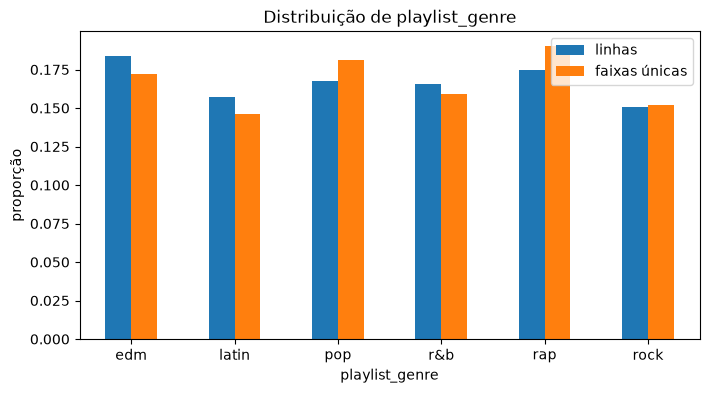

In [85]:
counts = pd.DataFrame({
    "linhas": df[TARGET].value_counts(),
    "faixas únicas": unique_tracks[TARGET].value_counts(),
})
props = counts / counts.sum()
display(pd.concat([counts, props.round(3).add_suffix(" (prop.)")], axis=1))
print(f"Razão maior/menor classe (faixas únicas): {counts['faixas únicas'].max() / counts['faixas únicas'].min():.2f}")

ax = props.plot.bar(figsize=(8, 4), rot=0)
ax.set_ylabel("proporção")
ax.set_title(f"Distribuição de {TARGET}")
ax.legend()
plt.show()

**Rótulos conflitantes.** Faixas que aparecem em mais de um gênero: quais pares de gêneros dividem faixas? (diagonal = número de faixas multigênero daquele gênero)

In [86]:
multi = df[df["track_id"].isin(genres_per_track[genres_per_track > 1].index)]

# one_hot marca o gênero de cada linha; o max por faixa junta todas as playlists da mesma faixa
encoded = one_hot(multi[["track_id", TARGET]], [TARGET], drop=True)
genre_onehot = encoded.groupby("track_id").max()
genre_onehot.columns = genre_onehot.columns.str.removeprefix(f"{TARGET}_").str.removesuffix("_onehot")
genre_onehot = genre_onehot.sort_index(axis=1)

multi_class = genre_onehot.T @ genre_onehot
multi_class = multi_class.mask(np.eye(len(multi_class), dtype=bool), 0)

multi_class

,edm,latin,pop,r&b,rap,rock
edm,0,214,413,169,100,8
latin,214,0,333,178,192,8
pop,413,333,0,362,85,124
r&b,169,178,362,0,201,45
rap,100,192,85,201,0,23
rock,8,8,124,45,23,0


- Classes quase balanceadas: 15–18% por linha, 15–19% por faixa única; razão maior/menor ≈ 1,3.
- Deduplicar muda a ordem: `edm` é a maior classe nas linhas, `rap` nas faixas únicas.
- Pares que mais dividem faixas: `pop`–`edm`, `pop`–`r&b`, `pop`–`latin`. `rock` quase não divide.

### 2.4 Distribuição das variáveis explicativas

- Numéricas: histogramas/boxplots.
- Categóricas: contagens.

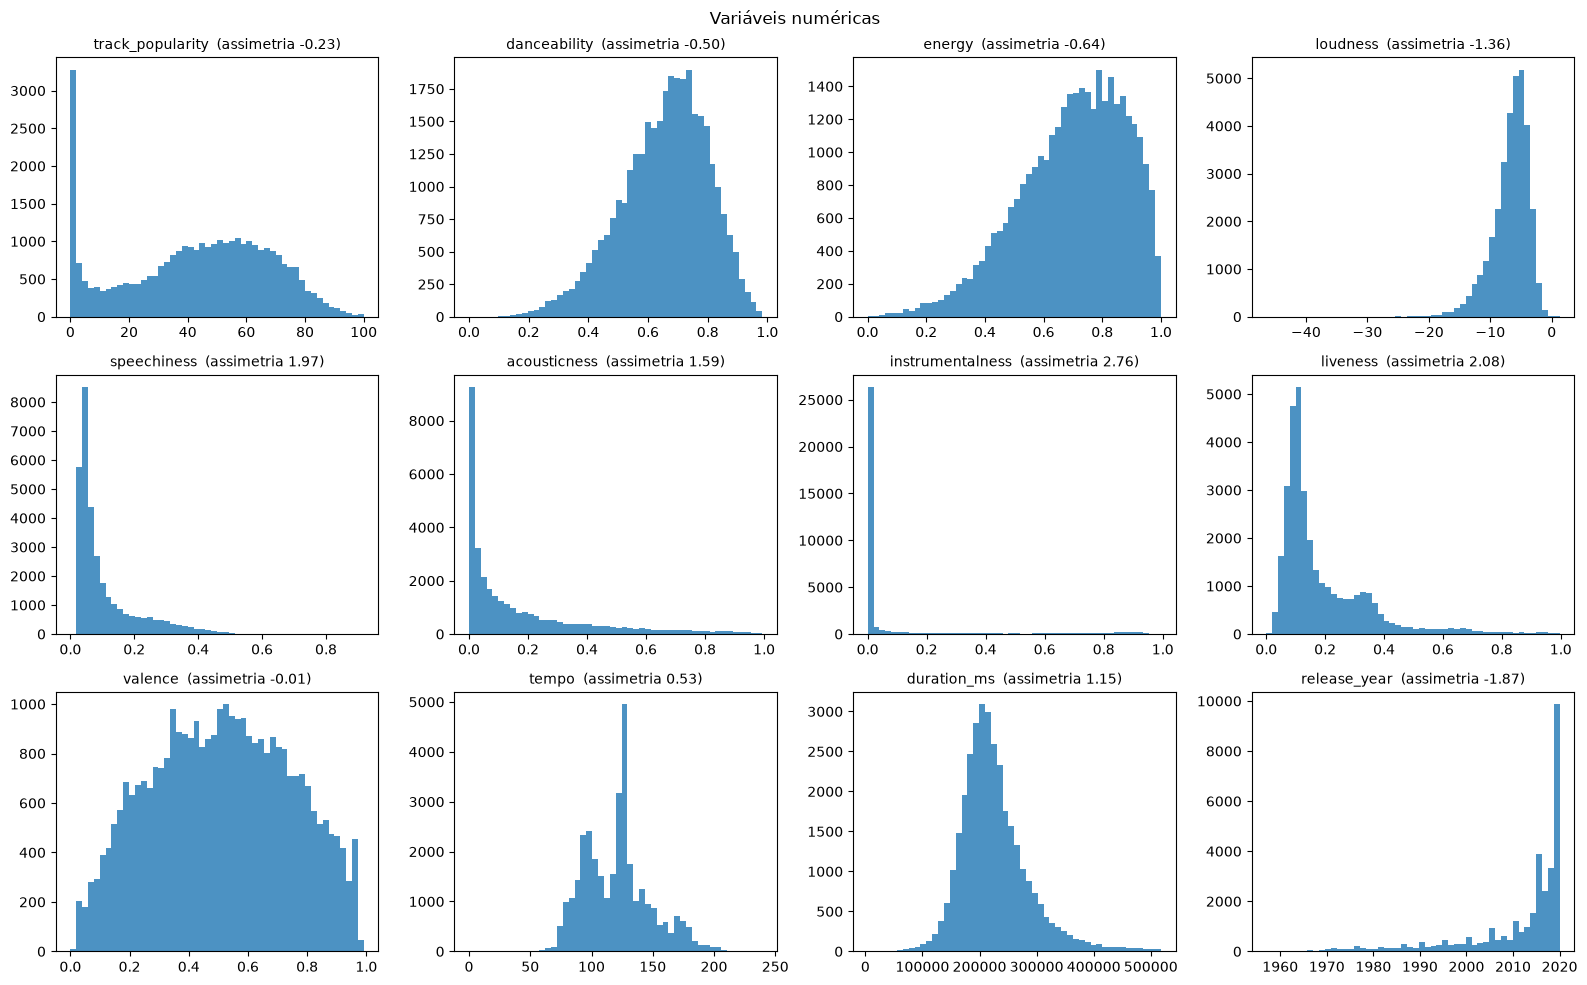

In [87]:
release_year = df[DATE_COL].str[:4].astype(int)
num_data = df[NUM_COLS].assign(release_year=release_year)

fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for ax, col in zip(axes.flat, num_data.columns):
    ax.hist(num_data[col], bins=50, color="tab:blue", alpha=0.8)
    ax.set_title(f"{col}  (assimetria {num_data[col].skew():.2f})", fontsize=10)
fig.suptitle("Variáveis numéricas")
fig.tight_layout()
plt.show()

In [88]:
q1, q3 = num_data.quantile(0.25), num_data.quantile(0.75)
iqr = q3 - q1
outliers = ((num_data < q1 - 1.5 * iqr) | (num_data > q3 + 1.5 * iqr)).mean()

summary = num_data.describe().T
summary["assimetria"] = num_data.skew()
summary["% outliers (IQR)"] = (100 * outliers).round(1)
summary.round(3)

,count,mean,std,min,25%,50%,75%,max,assimetria,% outliers (IQR)
track_popularity,32833.0,42.477,24.984,0.000,24.000,45.000,62.000,100.000,-0.233,0.0
danceability,32833.0,0.655,0.145,0.000,0.563,0.672,0.761,0.983,-0.504,0.9
energy,32833.0,0.699,0.181,0.000,0.581,0.721,0.840,1.000,-0.636,0.8
loudness,32833.0,-6.719,2.988,-46.448,-8.171,-6.166,-4.645,1.275,-1.364,3.1
speechiness,32833.0,0.107,0.101,0.000,0.041,0.062,0.132,0.918,1.967,9.7
acousticness,32833.0,0.175,0.220,0.000,0.015,0.080,0.255,0.994,1.595,6.7
instrumentalness,32833.0,0.085,0.224,0.000,0.000,0.000,0.005,0.994,2.759,21.4
liveness,32833.0,0.190,0.154,0.000,0.093,0.127,0.248,0.996,2.077,5.6
valence,32833.0,0.511,0.233,0.000,0.331,0.512,0.693,0.991,-0.005,0.0
tempo,32833.0,120.881,26.904,0.000,99.960,121.984,133.918,239.440,0.529,1.7


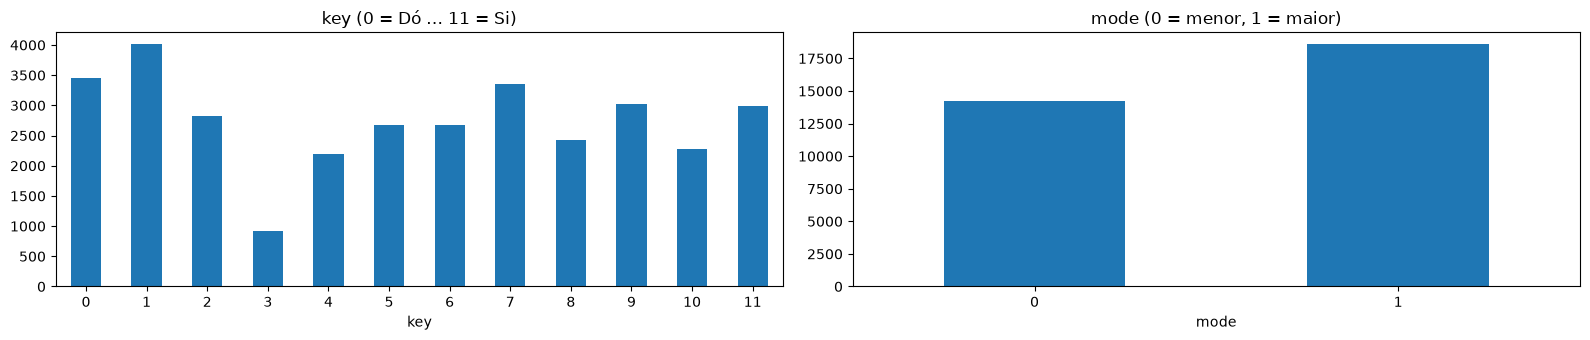

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 3.5))

# os valores de key incluem os semitons também 
df["key"].value_counts().sort_index().plot.bar(ax=axes[0], rot=0, title="key (0 = Dó … 11 = Si)")
df["mode"].value_counts().sort_index().plot.bar(ax=axes[1], rot=0, title="mode (0 = menor, 1 = maior)")
fig.tight_layout()
plt.show()

- Escalas muito diferentes: `duration_ms` ~10⁵, `tempo` ~10², `loudness` em dB negativo, atributos de áudio em 0–1.
- Assimetria forte à direita: `instrumentalness` (2,8), `liveness` (2,1), `speechiness` (2,0), `acousticness` (1,6). À esquerda: `loudness` (−1,4), mínimo −46 dB.
- `instrumentalness` tem 21% de outliers pelo IQR só porque a mediana é ~0: a regra do IQR não serve aqui.
- `track_popularity` tem pico em 0 (8% das linhas) separado do resto da distribuição.
- `release_year` vai de 1957 a 2020, concentrado depois de 2010.
- `key` e `mode` sem categoria rara; `mode` = 1 em 57%.

### 2.5 Relação entre variáveis

Correlação entre preditores

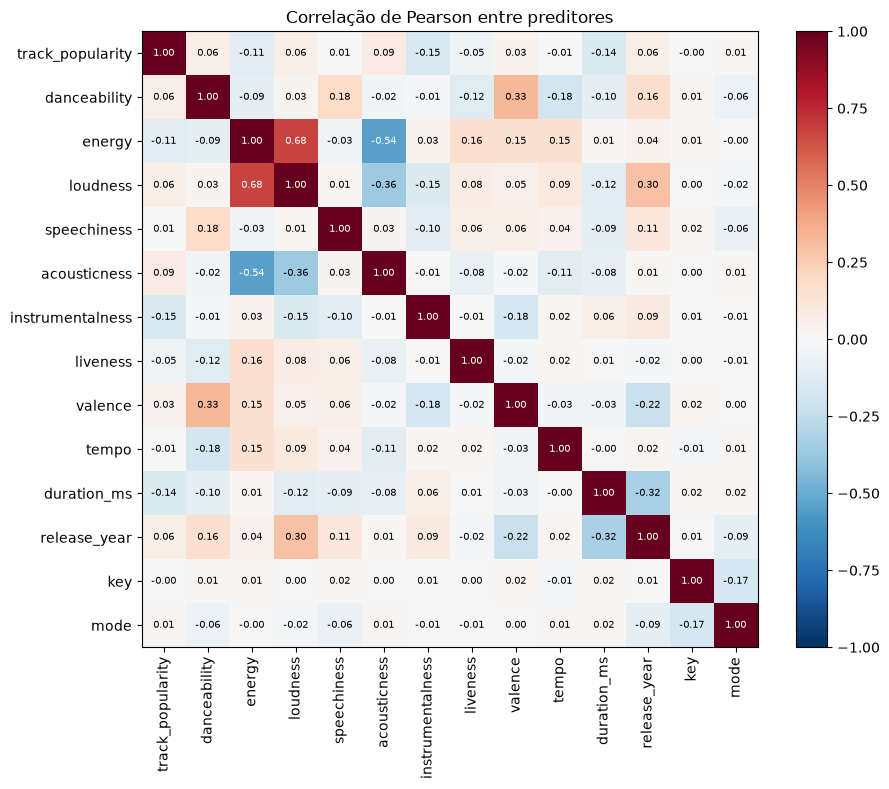

r
energy       loudness      0.676625
             acousticness -0.539745
loudness     acousticness -0.361638
danceability valence       0.330523
duration_ms  release_year -0.321790

In [90]:
corr = num_data.assign(key=df["key"], mode=df["mode"]).corr()

fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=90)
ax.set_yticks(range(len(corr)), corr.columns)
corr_values = corr.to_numpy()   # array numpy: tipo numérico claro para o Pylance
for i in range(len(corr)):
    for j in range(len(corr)):
        r = corr_values[i, j]
        ax.text(j, i, f"{r:.2f}", ha="center", va="center", fontsize=7,
                color="white" if abs(r) > 0.5 else "black")
fig.colorbar(im, ax=ax)
ax.set_title("Correlação de Pearson entre preditores")
plt.show()

pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
pairs.sort_values(key=abs, ascending=False).head(5).rename("r").to_frame()

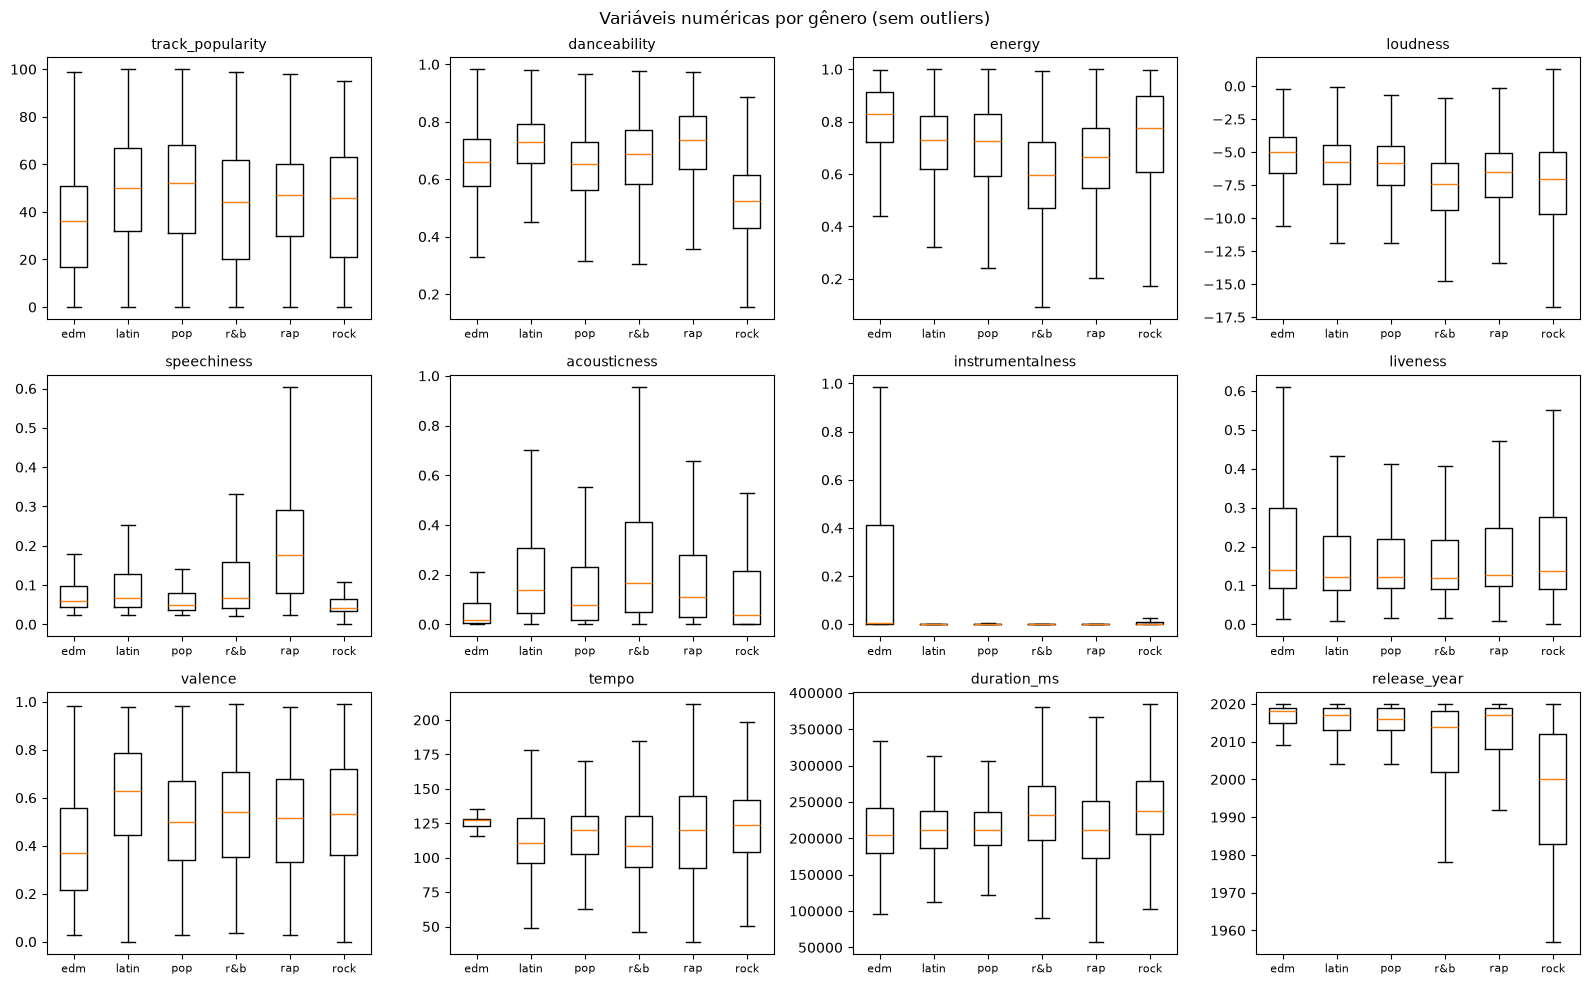

In [91]:
genres = sorted(df[TARGET].unique())

fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for ax, col in zip(axes.flat, num_data.columns):
    ax.boxplot([num_data.loc[df[TARGET] == g, col] for g in genres], tick_labels=genres, showfliers=False)
    ax.set_title(col, fontsize=10)
    ax.tick_params(axis="x", labelsize=8)
fig.suptitle("Variáveis numéricas por gênero (sem outliers)")
fig.tight_layout()
plt.show()

**Poder de separação de cada variável.** η² = variância entre classes / variância total (0 = médias iguais em todos os gêneros; 1 = separa perfeitamente). Olha só a média, então é um ranking aproximado.

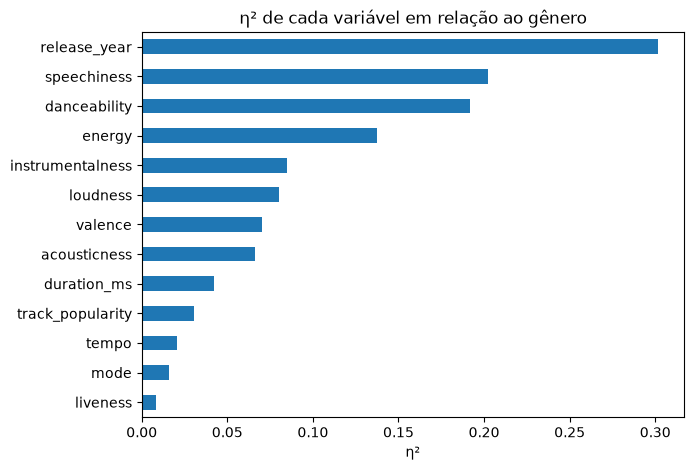

key,0,1,2,3,4,5,6,7,8,9,10,11
playlist_genre,,,,,,,,,,,,
edm,0.097,0.126,0.083,0.032,0.064,0.098,0.090,0.102,0.078,0.072,0.063,0.097
latin,0.111,0.120,0.072,0.026,0.059,0.079,0.087,0.107,0.074,0.098,0.072,0.094
pop,0.121,0.115,0.076,0.032,0.070,0.087,0.079,0.094,0.074,0.095,0.064,0.093
r&b,0.096,0.133,0.081,0.029,0.057,0.092,0.086,0.096,0.076,0.087,0.076,0.089
rap,0.085,0.163,0.078,0.022,0.060,0.065,0.083,0.093,0.083,0.076,0.095,0.098
rock,0.126,0.068,0.132,0.025,0.096,0.067,0.059,0.123,0.057,0.131,0.042,0.074


In [92]:
def eta_squared(x, y):
    """Fração da variância de x explicada pela média de cada classe de y."""
    return ((x.groupby(y).transform("mean") - x.mean()) ** 2).sum() / ((x - x.mean()) ** 2).sum()


eta = num_data.assign(mode=df["mode"]).apply(lambda col: eta_squared(col, df[TARGET])).sort_values()
ax = eta.plot.barh(figsize=(7, 5), title="η² de cada variável em relação ao gênero")
ax.set_xlabel("η²")
plt.show()

# key é nominal: comparar a distribuição por gênero em vez da média
pd.crosstab(df[TARGET], df["key"], normalize="index").round(3)

**Projeção PCA.** `pca` da biblioteca sobre as numéricas padronizadas (`key` fica de fora por ser nominal). Mostra se os gêneros se separam com combinações lineares das variáveis.

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,PC11,PC12
variância explicada,0.182,0.138,0.119,0.096,0.089,0.081,0.071,0.067,0.054,0.051,0.033,0.018
acumulada,0.182,0.319,0.439,0.535,0.624,0.705,0.776,0.844,0.898,0.949,0.982,1.000


,PC1,PC2
track_popularity,-0.05,-0.31
danceability,-0.02,-0.49
energy,0.60,0.10
loudness,0.57,-0.15
speechiness,0.02,-0.32
acousticness,-0.47,-0.14
instrumentalness,-0.05,0.24
liveness,0.15,0.14
valence,0.08,-0.25
tempo,0.17,0.16


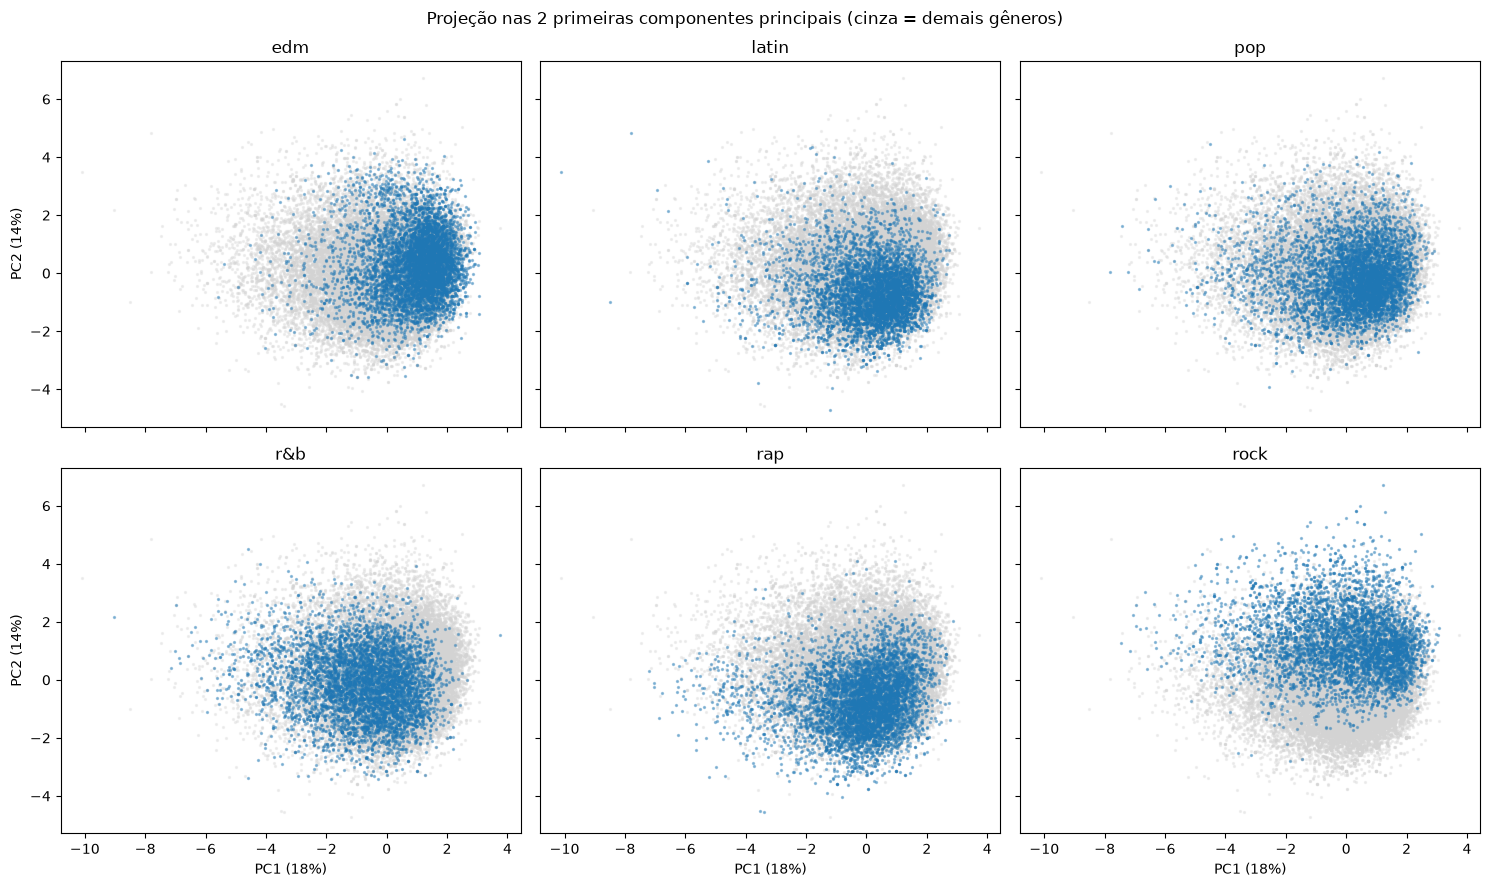

In [93]:
eda_pca = pca(n_components=num_data.shape[1], standardize=True)
scores = eda_pca.fit_transform(num_data.to_numpy())

# Com standardize=True cada coluna tem variância 1, então a variância total é o nº de colunas
explained = scores.var(axis=0) / num_data.shape[1]
pc_names = [f"PC{i + 1}" for i in range(len(explained))]
display(pd.DataFrame({"variância explicada": explained, "acumulada": explained.cumsum()}, index=pc_names).round(3).T)
display(pd.DataFrame(eda_pca.components[:, :2], index=num_data.columns, columns=pc_names[:2]).round(2))

fig, axes = plt.subplots(2, 3, figsize=(15, 9), sharex=True, sharey=True)
for ax, g in zip(axes.flat, genres):
    is_g = (df[TARGET] == g).to_numpy()
    ax.scatter(scores[~is_g, 0], scores[~is_g, 1], s=2, c="lightgray", alpha=0.3, rasterized=True)
    ax.scatter(scores[is_g, 0], scores[is_g, 1], s=2, alpha=0.4, rasterized=True)
    ax.set_title(g)
for ax in axes[1]:
    ax.set_xlabel(f"PC1 ({explained[0]:.0%})")
for ax in axes[:, 0]:
    ax.set_ylabel(f"PC2 ({explained[1]:.0%})")
fig.suptitle("Projeção nas 2 primeiras componentes principais (cinza = demais gêneros)")
fig.tight_layout()
plt.show()

**Vazamento.** Colunas que vêm da playlist (e não da música) e quanto delas determina o gênero sozinha.

In [94]:
for col in ["playlist_subgenre", "playlist_name", "playlist_id", "track_album_id"]:
    single_genre = (df.groupby(col)[TARGET].nunique() == 1).mean()
    print(f"{col:18s} {df[col].nunique():6d} valores; {single_genre:6.1%} mapeiam para um único gênero")

pd.crosstab(df["playlist_subgenre"], df[TARGET])

playlist_subgenre      24 valores; 100.0% mapeiam para um único gênero
playlist_name         449 valores;  98.9% mapeiam para um único gênero
playlist_id           471 valores;  98.9% mapeiam para um único gênero
track_album_id      22545 valores;  92.1% mapeiam para um único gênero


playlist_genre,edm,latin,pop,r&b,rap,rock
playlist_subgenre,,,,,,
album rock,0,0,0,0,0,1065
big room,1206,0,0,0,0,0
classic rock,0,0,0,0,0,1296
dance pop,0,0,1298,0,0,0
electro house,1511,0,0,0,0,0
electropop,0,0,1408,0,0,0
gangster rap,0,0,0,0,1458,0
hard rock,0,0,0,0,0,1485
hip hop,0,0,0,0,1322,0


- Correlações moderadas: `energy`–`loudness` (0,68), `energy`–`acousticness` (−0,54). Nenhum par acima de 0,7.
- Mais discriminantes (η²): `release_year` (0,30), `speechiness` (0,20), `danceability` (0,19), `energy` (0,14). Quase nada: `liveness`, `mode`, `key`.
- `rock`: mais antigo (mediana 2000), menos dançante, menos `speechiness`. `rap`: `speechiness` alto. `edm`: mais `energy` e `instrumentalness`.
- η² só compara médias: `tempo` tem η² baixo, mas no `edm` é muito concentrado (~120–135 BPM). Modelos que usam a dispersão por classe (QDA, KNN) podem aproveitar isso.
- `playlist_subgenre` determina o gênero em 100% dos casos; `playlist_name`/`playlist_id` em ~99%.
- PCA: PC1 ≈ energia/volume × acústico (separa `edm` de `r&b`); PC2 ≈ faixa longa e antiga × dançante e falada (isola `rock`, oposto a `rap`/`latin`). As duas explicam só 32% da variância e `pop` fica no meio de todos.
- São precisas 10 das 12 componentes para 90% da variância: pouca redundância entre as variáveis.

### 2.6 Conclusões da EDA


- O que tratar no pré-processamento:
    - **Deduplicar por `track_id`** (na 3.1, antes da divisão). `df.duplicated()` encontra 0 linhas: não basta.
    - Faixas em mais de um gênero (~1,7 mil): decidir entre manter a 1ª ocorrência ou descartar.
    - Remover a faixa com `tempo == 0` (análise de áudio inválida).
    - Remover identificadores e textos (`ID_COLS`, `TEXT_COLS`) e `playlist_subgenre`.
    - `track_album_release_date` → `release_year` (é a variável mais discriminante).
    - `key` nominal: one-hot ou descartar (η² ≈ 0). `mode` binária: manter como está.
    - Padronizar as numéricas (escalas de 0–1 a ~10⁵; KNN, regressão logística e rede neural são sensíveis).
    - Opcional: `log1p` em `speechiness`, `acousticness`, `instrumentalness`, `liveness` (assimetria > 1,5).
    - Reduzir dimensão com PCA não deve compensar (10 de 12 componentes para 90% da variância).
- Riscos (vazamento, colinearidade, outliers, desbalanceamento):
    - **Vazamento por duplicata**: 32 833 linhas, 28 356 faixas. A mesma faixa em treino e teste infla a métrica. Há ainda ~2,1 mil pares com mesmo nome+artista e `track_id` diferente (relançamentos).
    - **Vazamento por coluna**: `playlist_subgenre` (100%), `playlist_name`/`playlist_id` (~99%) entregam o gênero.
    - **Vazamento por álbum** (mais sutil): 92% dos álbuns têm um só gênero; um split aleatório põe faixas do mesmo álbum nos dois lados.
    - **Rótulo ruidoso**: o mesmo áudio com gêneros diferentes limita a acurácia máxima; esperar confusão entre `pop`, `edm`, `latin` e `r&b`.
    - Colinearidade moderada (`energy`–`loudness` 0,68). Pesa mais na QDA (covariância por classe) que no KNN.
    - Outliers reais (não erros): `loudness` até −46 dB, caudas longas nos atributos 0–1.
    - Desbalanceamento leve (razão ≈ 1,3): estratificar a divisão e reportar F1-macro junto com a acurácia.

## 3. Divisão treino/teste

### 3.1 Remoção de linhas duplicadas

In [95]:
# Quantos gêneros distintos cada faixa tem
n_genres = df.groupby("track_id")[TARGET].transform("nunique")

# Usa apenas faixas que possuem 1 único gênero
df_clean = df[n_genres == 1]

# Remove as duplicatas de um único gênero por faixa
df_clean = df_clean.drop_duplicates("track_id")

# Remove faixas com aúdio inválido
df_clean = df_clean[df_clean["tempo"] > 0]

# Organiza os índices para 0,1,2,...
df_clean = df_clean.reset_index(drop=True)

print(f"Todas as faixas são únicas? {df_clean["track_id"].is_unique}")

rows_df = len(df)
rows_clean_df = len(df_clean)

print(f"{rows_df} linhas -> {rows_clean_df} faixas -> {rows_df - rows_clean_df} removidas")

Todas as faixas são únicas? True
32833 linhas -> 26668 faixas -> 6165 removidas


### 3.2 Divisão

Separação em **dados de treino** e **dados de teste**

In [ ]:
# Sorteia uma fração dos dados 
test_df = df_clean.groupby(TARGET).sample(frac=TEST_SIZE, random_state=SEED)

# Remove os dados que estão na fatia de teste
# O que sobra será usado como dados de treino
train_df = df_clean.drop(test_df.index)

# Embaralha as linhas
train_df = train_df.sample(frac=1, random_state=SEED).reset_index(drop=True)

# Ordena os índices para 0,1,2,...
test_df = test_df.reset_index(drop=True)

### 3.3 Conferência

Tamanho final dos conjuntos de teste e treino

In [97]:
print(f"Tamanho dos dados originais: {len(df_clean)}")
print(f"Tamanho dos dados de treino (fração {1 - TEST_SIZE}): {len(train_df)}")
print(f"Tamanho dos dados de teste (fração {TEST_SIZE}): {len(test_df)}")

Tamanho dos dados originais: 26668
Tamanho dos dados de treino (fração 0.8): 21335
Tamanho dos dados de teste (fração 0.2): 5333


## 4. Pré-processamento

Todo parâmetro (média, desvio, categorias do one-hot) é calculado **só no treino** e aplicado no outro conjunto. As subseções registram as decisões; a 4.6 junta tudo numa função, reutilizada em cada fold (seção 6) e no teste (seção 8).

### 4.1 Remoção de colunas

Colunas que não serão usadas:

| Coluna | Motivo |
|---|---|
| `track_id`, `track_album_id`, `playlist_id` | identificadores do Spotify; irrelevantes |
| `track_name`, `track_artist`, `track_album_name` | texto livre |
| `playlist_name` | texto |
| `playlist_subgenre` | vazamento: cada subgênero pertence a um único gênero (100%) |
| `track_album_release_date` | substituída por `release_year` (numérica) |

In [98]:
# Colunas que não vão ser usadas no modelo
DROP_COLS = ID_COLS + TEXT_COLS + ["playlist_subgenre", DATE_COL]

# Colunas que precisam ser colocadas na mesma escala
SCALE_COLS = NUM_COLS + ["release_year"]

# Função que deixa apenas colunas que o modelo pode usar:
#   1. Converte "release_year" para apenas ano (numérico)
#   2. Trata a coluna "key" como categoria (evita ordenação)
#   3. Apaga as colunas definidas acima

def basic_transform(data):
    out = data.copy()
    
    # 1 cria a coluna "year"
    out["release_year"] = out[DATE_COL].str[:4].astype(int)
    
    # 2 converte "key" para categórica
    out["key"] = out["key"].astype(str)
    
    # 3 remove as colunas necessárias
    out = out.drop(columns=DROP_COLS)
    return out

### 4.2 Valores ausentes

Confirmação de que não existem valores vazios

In [99]:
print(basic_transform(train_df).isna().sum().sum() != 0)

False


### 4.3 Função de pré-processamento e matrizes finais

In [100]:
def fit_preprocess(train):
    
    # Aplica a transformação de 4.1 nos dados fornecidos
    data = basic_transform(train)
    
    # Aplica codificação one-hot na coluna "key" (notas)
    encoded = one_hot(data, ["key"], drop=True)
    
    # Ordena as colunas "_onehot" que foram criadas na codificação
    onehot_cols = sorted(c for c in encoded.columns if c.endswith("_onehot"))
    
    # Ordena a primeira coluna do onehot
    # "key_0_onehot" vira categoria de referência: definida a partir das outras
    onehot_cols = onehot_cols[1:]
    
    # Usa a função de padronização, salvando apenas o dicionário com
    # média e desvio de cada coluna
    _, scale_params = standardization(data, SCALE_COLS)
    
    # Retorna as colunas do Onehot e os parâmetros de escala (média e desvio)
    return {"onehot_cols": onehot_cols, "scale": scale_params}

## 5. Modelos candidatos

| Modelo | Classe/função da biblioteca | Hiperparâmetros | Por que testar |
|---|---|---|---|
| Baseline | `MajorityClass` (5.1, neste notebook) | — | referência mínima: sempre o gênero mais frequente |
| LDA | `LDA` | `reg_param` | fronteiras lineares; uma covariância para todos os gêneros |
| QDA | `QDA` | `reg_param` | fronteiras quadráticas; usa a dispersão de cada gênero (ex.: `tempo` no `edm`) |
| Regressão logística | `LogisticRegression` + um-contra-todos (5.4) | — (`learn_rate` fixo) | linear e discriminativa; dá probabilidades |
| KNN | `KNN` | `k` | não paramétrico; fronteiras locais, não lineares |
| Rede neural (obrigatória) | ver `classification_pipeline_neural_networks.ipynb` |  |  |

### Teste rápido dos candidatos

Cada modelo é treinado e avaliado aqui, com hiperparâmetros padrão (`reg_param = 0`, `learn_rate = 5`, `k = 15`), para conferir que roda e ter uma primeira ideia do desempenho. A escolha de hiperparâmetros com validação cruzada fica na seção 6, e o conjunto de teste não é usado.

- Holdout: 20% do `train_df` (estratificado por gênero) vira validação; o pré-processamento é ajustado só nos outros 80%.
- Métricas: F1-macro (principal) e acurácia na validação. O F1-macro de treino usa uma amostra fixa de 1000 linhas para economia de tempo.

In [101]:
import time


def apply_preprocess(data, params):
    """Aplica em `data` os parâmetros calculados por fit_preprocess (4.3). Retorna X (numpy) e y.
    """
    out = one_hot(basic_transform(data), ["key"], drop=True)

    # Tom ausente neste conjunto vira coluna de zeros; key_0 (referência) fica de fora de X
    for col in params["onehot_cols"]:
        if col not in out.columns:
            out[col] = 0

    # Padroniza com média e desvio do treino (desvio 0 = coluna constante no treino)
    for col, p in params["scale"].items():
        out[col] = (out[col] - p["mean"]) / p["std"] if p["std"] > 0 else 0.0

    X = out[SCALE_COLS + ["mode"] + params["onehot_cols"]].to_numpy(dtype=float)
    y = out[TARGET].to_numpy()
    return X, y


# Holdout dentro do treino (o test_df não é usado nesta seção)
val_part = train_df.groupby(TARGET).sample(frac=0.2, random_state=SEED)
fit_part = train_df.drop(val_part.index)

holdout_params = fit_preprocess(fit_part)
X_fit, y_fit = apply_preprocess(fit_part, holdout_params)
X_val, y_val = apply_preprocess(val_part, holdout_params)

LABELS = sorted(np.unique(y_fit))   # ordem dos gêneros nas métricas e nas probabilidades
train_sample = np.random.default_rng(SEED).choice(len(X_fit), size=1000, replace=False)


def macro_f1(y_true, y_pred):
    """F1 médio dos gêneros. Gênero com precisão e recall 0 vira NaN na biblioteca: conta como 0."""
    return float(np.nan_to_num(f1_score(y_true, y_pred, LABELS)).mean())


quick_results = {}


def quick_check(name, model):
    """Treina 'model' no holdout de treino, avalia na validação e guarda o resultado em quick_results."""
    start = time.perf_counter()
    model.fit(X_fit, y_fit)
    fit_seconds = time.perf_counter() - start

    start = time.perf_counter()
    y_pred = model.predict(X_val)
    predict_seconds = time.perf_counter() - start

    quick_results[name] = {
        "F1-macro treino": macro_f1(y_fit[train_sample], model.predict(X_fit[train_sample])),
        "F1-macro validação": macro_f1(y_val, y_pred),
        "acurácia validação": accuracy(y_val, y_pred),
        "treino (s)": fit_seconds,
        "previsão (s)": predict_seconds,
    }
    return pd.DataFrame(quick_results[name], index=[name]).round(3)


print(f"Treino do holdout: {X_fit.shape} | validação: {X_val.shape}")

Treino do holdout: (17069, 24) | validação: (4266, 24)


### 5.1 Baseline

Sempre prevê o gênero mais frequente no treino. Qualquer modelo útil precisa superar esse resultado.

In [102]:
class MajorityClass:
    """Baseline: prevê sempre o gênero mais frequente; probabilidades = frequências do treino."""

    def fit(self, X, y):
        self.classes, counts = np.unique(y, return_counts=True)
        self.priors = counts / counts.sum()
        self.majority = self.classes[np.argmax(counts)]
        return self

    def predict(self, X):
        return np.full(len(X), self.majority)

    def predict_probabilities(self, X):
        return np.tile(self.priors, (len(X), 1))

quick_check("Baseline", MajorityClass())

,F1-macro treino,F1-macro validação,acurácia validação,treino (s),previsão (s)
Baseline,0.053,0.053,0.187,0.028,0.0


### 5.2 LDA

Uma covariância comum a todos os gêneros com fronteiras lineares. `reg_param` $\in$ [0, 1] puxa a covariância para a diagonal (0 = sem regularização).

In [103]:
LDA_GRID = {"reg_param": [0.0, 0.1, 0.3, 0.5, 0.9]}

lda = LDA()
display(quick_check("LDA", lda))

# Probabilidade de cada gênero para uma faixa de cada gênero da validação
# (a validação sai agrupada por gênero: as primeiras linhas seriam todas do mesmo)
examples = [np.flatnonzero(y_val == g)[0] for g in LABELS]
pd.DataFrame(lda.predict_probabilities(X_val[examples]), columns=lda.classes,
             index=pd.Index(y_val[examples], name="gênero real")).round(3)

,F1-macro treino,F1-macro validação,acurácia validação,treino (s),previsão (s)
LDA,0.491,0.502,0.508,0.035,0.003


,edm,latin,pop,r&b,rap,rock
gênero real,,,,,,
edm,0.694,0.106,0.105,0.016,0.075,0.004
latin,0.072,0.425,0.256,0.119,0.123,0.005
pop,0.357,0.142,0.342,0.048,0.068,0.042
r&b,0.020,0.101,0.062,0.284,0.055,0.478
rap,0.019,0.108,0.078,0.533,0.022,0.240
rock,0.060,0.116,0.208,0.377,0.044,0.196


### 5.3 QDA

Uma covariância por gênero com fronteiras quadráticas. Pode aproveitar dispersões diferentes entre gêneros (ex.: `tempo` concentrado no `edm`, seção 2.5). `reg_param` reduz o sobreajuste das 6 matrizes.

In [104]:
QDA_GRID = {"reg_param": [0.0, 0.1, 0.3, 0.5, 0.7, 0.9]}

qda = QDA()
quick_check("QDA", qda)

,F1-macro treino,F1-macro validação,acurácia validação,treino (s),previsão (s)
QDA,0.501,0.482,0.497,0.039,0.012


### 5.4 Regressão logística (um-contra-todos)

A `LogisticRegression` da biblioteca só aceita 2 classes. Para 6 gêneros: um modelo por gênero (gênero × resto); a previsão é o gênero de maior probabilidade.

Sem hiperparâmetro para buscar: a implementação não tem regularização e `learn_rate` só muda a convergência. Num teste no treino, com 0,5 nenhum dos 6 modelos converge em 5000 iterações e com 5,0 todos convergem, com acurácia e F1 iguais até a 4ª casa.

In [105]:
# Talvez seja interessante a gente colocar isso na biblioteca se der tempo

class OneVsRestLogistic:
    """LogisticRegression da biblioteca (2 classes) estendida para várias classes por um-contra-todos."""

    def __init__(self, learn_rate=5.0, max_iter=5000):
        self.learn_rate = learn_rate
        self.max_iter = max_iter

    def fit(self, X, y):
        self.classes = np.unique(y)
        self.models = []
        for c in self.classes:
            model = LogisticRegression(learn_rate=self.learn_rate, max_iter=self.max_iter)
            model.fit(X, (y == c).astype(int))   # 1 = gênero c, 0 = resto
            self.models.append(model)
        return self

    def predict_probabilities(self, X):
        scores = np.column_stack([m.predict_probabilities(X)[:, 1] for m in self.models])
        return scores / scores.sum(axis=1, keepdims=True)   # normaliza para somar 1

    def predict(self, X):
        return self.classes[np.argmax(self.predict_probabilities(X), axis=1)]

quick_check("Regressão logística", OneVsRestLogistic())

,F1-macro treino,F1-macro validação,acurácia validação,treino (s),previsão (s)
Regressão logística,0.482,0.499,0.519,5.34,0.001


### 5.5 KNN

Escolha baseada nos `k` vizinhos mais próximos.

In [106]:
KNN_GRID = {"k": [15, 35, 75]}

# ~3 min: a KNN da biblioteca mede as distâncias ponto a ponto
quick_check("KNN", KNN(k=15))

,F1-macro treino,F1-macro validação,acurácia validação,treino (s),previsão (s)
KNN,0.575,0.541,0.548,0.0,115.95


### 5.6 Resumo do teste rápido

,F1-macro treino,F1-macro validação,acurácia validação,treino (s),previsão (s)
Baseline,0.053,0.053,0.187,0.028,0.000
LDA,0.491,0.502,0.508,0.035,0.003
QDA,0.501,0.482,0.497,0.039,0.012
Regressão logística,0.482,0.499,0.519,5.340,0.001
KNN,0.575,0.541,0.548,0.000,115.950


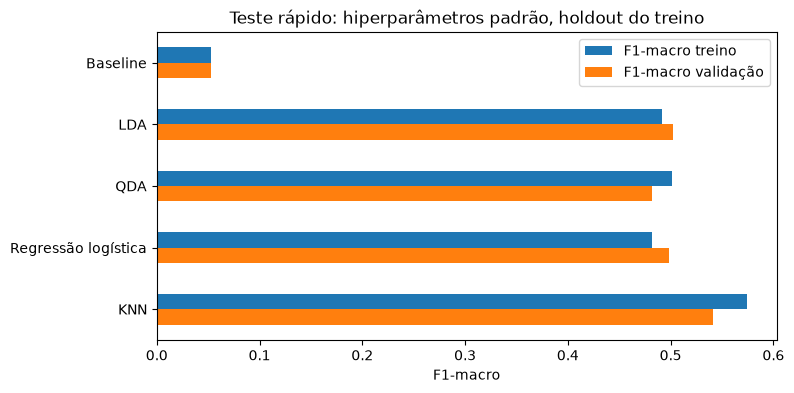

In [107]:
quick_summary = pd.DataFrame.from_dict(quick_results, orient="index")
display(quick_summary.round(3))

ax = quick_summary[["F1-macro treino", "F1-macro validação"]].plot.barh(figsize=(8, 4))
ax.invert_yaxis()
ax.set_xlabel("F1-macro")
ax.set_title("Teste rápido: hiperparâmetros padrão, holdout do treino")
plt.show()

- Todos os modelos superam a baseline com folga: F1-macro de 0,05 para 0,48–0,54.
- KNN (`k = 15`) é o melhor (F1-macro 0,54 na validação) e o mais lento (~2,7 min para prever ~4,3 mil faixas).
- LDA, QDA e regressão logística ficam entre 0,48 e 0,50, com treino $\approx$ validação: não há sobreajuste. O limite parece ser a forma das fronteiras (lineares/quadráticas) e o ruído de rótulo visto na EDA.
- QDA abaixo do LDA: as 6 covariâncias por gênero não compensaram sem regularização. Testar `reg_param` na seção 6.
- KNN tem a maior diferença treino–validação (0,58 × 0,54): vale testar `k` maiores na seção 6.
- É um único holdout com hiperparâmetros padrão; diferenças de 0,01–0,02 (ex.: LDA × regressão logística) estão dentro do ruído. A comparação que vale é a das seções 6 e 7.

## 6. Validação e seleção de hiperparâmetros


### 6.1 Função de validação

In [108]:
from ml_library.model_selection.kfold import kfold_indices

splits = kfold_indices(n=len(train_df), k=N_FOLDS)

folds_data = []
for train_idx, val_idx in splits:
    fold_train = train_df.iloc[train_idx]
    fold_val = train_df.iloc[val_idx]

    fold_params = fit_preprocess(fold_train)
    X_tr, y_tr = apply_preprocess(fold_train, fold_params)
    X_va, y_va = apply_preprocess(fold_val, fold_params)

    folds_data.append((X_tr, y_tr, X_va, y_va))


def evaluate_kfold(model_class, params=None):
    """Avalia um modelo nos 5 folds e retorna média e desvio de F1-macro e acurácia."""
    if params is None:
        params = {}

    f1_scores = []
    acc_scores = []

    for X_tr, y_tr, X_va, y_va in folds_data:
        model = model_class(**params)
        model.fit(X_tr, y_tr)
        y_pred = model.predict(X_va)

        f1_scores.append(macro_f1(y_va, y_pred))
        acc_scores.append(accuracy(y_va, y_pred))

    return {
        "mean_macro_f1": float(np.mean(f1_scores)),
        "std_macro_f1": float(np.std(f1_scores)),
        "mean_accuracy": float(np.mean(acc_scores)),
        "std_accuracy": float(np.std(acc_scores)),
    }


print(f"{N_FOLDS} folds preparados.")

5 folds preparados.


### 6.2 Busca de hiperparâmetros — por modelo

In [109]:
cv_best_models = {}

# 1. Baseline
print("Avaliando Baseline")
res_base = evaluate_kfold(MajorityClass)
print(f"  Baseline -> F1-macro: {res_base['mean_macro_f1']:.4f} (+/- {res_base['std_macro_f1']:.4f}) | Acc: {res_base['mean_accuracy']:.4f}")  # <--- COLOQUE ESSA LINHA AQUI!
cv_best_models["Baseline"] = {"Melhores hiperparâmetros": "—", **res_base}

# 2. LDA 
print("Avaliando LDA")
lda_results = []
for reg in LDA_GRID["reg_param"]:
    res = evaluate_kfold(LDA, {"reg_param": reg})
    lda_results.append({"reg_param": reg, **res})
    print(f"  LDA (reg_param={reg}) -> F1-macro: {res['mean_macro_f1']:.4f} (+/- {res['std_macro_f1']:.4f}) | Acc: {res['mean_accuracy']:.4f}")

best_lda = max(lda_results, key=lambda x: x["mean_macro_f1"])
cv_best_models["LDA"] = {
    "Melhores hiperparâmetros": f"reg_param = {best_lda['reg_param']}",
    **{k: v for k, v in best_lda.items() if k != "reg_param"},
}

# 3. QDA 
print("\nAvaliando QDA")
qda_results = []
for reg in QDA_GRID["reg_param"]:
    res = evaluate_kfold(QDA, {"reg_param": reg})
    qda_results.append({"reg_param": reg, **res})
    print(f"  QDA (reg_param={reg}) -> F1-macro: {res['mean_macro_f1']:.4f} (+/- {res['std_macro_f1']:.4f}) | Acc: {res['mean_accuracy']:.4f}")

best_qda = max(qda_results, key=lambda x: x["mean_macro_f1"])
cv_best_models["QDA"] = {
    "Melhores hiperparâmetros": f"reg_param = {best_qda['reg_param']}",
    **{k: v for k, v in best_qda.items() if k != "reg_param"},
}

# 4. Regressão logística
print("\nAvaliando Regressão logística")
res_lr = evaluate_kfold(OneVsRestLogistic, {"learn_rate": 5.0, "max_iter": 5000})
print(f"  Regressão logística -> F1-macro: {res_lr['mean_macro_f1']:.4f} (+/- {res_lr['std_macro_f1']:.4f}) | Acc: {res_lr['mean_accuracy']:.4f}")
cv_best_models["Regressão logística"] = {
    "Melhores hiperparâmetros": "learn_rate = 5.0",
    **res_lr,
}

# 5. KNN 
print("\nAvaliando KNN")
knn_results = []
for k in KNN_GRID["k"]:
    res = evaluate_kfold(KNN, {"k": k})
    knn_results.append({"k": k, **res})
    print(f"  KNN (k={k}) -> F1-macro: {res['mean_macro_f1']:.4f} (+/- {res['std_macro_f1']:.4f}) | Acc: {res['mean_accuracy']:.4f}")

best_knn = max(knn_results, key=lambda x: x["mean_macro_f1"])
cv_best_models["KNN"] = {
    "Melhores hiperparâmetros": f"k = {best_knn['k']}",
    **{k: v for k, v in best_knn.items() if k != "k"},
}

Avaliando Baseline
  Baseline -> F1-macro: 0.0526 (+/- 0.0015) | Acc: 0.1873
Avaliando LDA
  LDA (reg_param=0.0) -> F1-macro: 0.4994 (+/- 0.0083) | Acc: 0.5046
  LDA (reg_param=0.1) -> F1-macro: 0.4985 (+/- 0.0079) | Acc: 0.5039
  LDA (reg_param=0.3) -> F1-macro: 0.4956 (+/- 0.0091) | Acc: 0.5012
  LDA (reg_param=0.5) -> F1-macro: 0.4922 (+/- 0.0097) | Acc: 0.4983
  LDA (reg_param=0.9) -> F1-macro: 0.4836 (+/- 0.0076) | Acc: 0.4906

Avaliando QDA
  QDA (reg_param=0.0) -> F1-macro: 0.4829 (+/- 0.0140) | Acc: 0.4985
  QDA (reg_param=0.1) -> F1-macro: 0.4812 (+/- 0.0133) | Acc: 0.4973
  QDA (reg_param=0.3) -> F1-macro: 0.4741 (+/- 0.0108) | Acc: 0.4899
  QDA (reg_param=0.5) -> F1-macro: 0.4700 (+/- 0.0110) | Acc: 0.4859
  QDA (reg_param=0.7) -> F1-macro: 0.4662 (+/- 0.0091) | Acc: 0.4821
  QDA (reg_param=0.9) -> F1-macro: 0.4608 (+/- 0.0070) | Acc: 0.4767

Avaliando Regressão logística
  Regressão logística -> F1-macro: 0.4943 (+/- 0.0080) | Acc: 0.5130

Avaliando KNN
  KNN (k=15) -> F1-m

## 7. Comparação de modelos

| Modelo | Melhores hiperparâmetros | Métrica principal (F1-macro val) | Acurácia val |
|---|---|---|---|
| **Baseline** | — | 0,0526 ± 0,0015 | 18,73% |
| **LDA** | `reg_param = 0.0` | 0,4994 ± 0,0083 | 50,46% |
| **QDA** | `reg_param = 0.0` | 0,4829 ± 0,0140 | 49,85% |
| **Regressão logística** | `learn_rate = 5.0` | 0,4943 ± 0,0080 | 51,30% |
| **KNN** | `k = 35` | **0,5450 ± 0,0051** | **55,32%** |

,Melhores hiperparâmetros,F1-macro val (média),F1-macro val (desvio),Acurácia val (média),Acurácia val (desvio)
Baseline,—,0.0526,0.0015,0.1873,0.0061
LDA,reg_param = 0.0,0.4994,0.0083,0.5046,0.0083
QDA,reg_param = 0.0,0.4829,0.0140,0.4985,0.0133
Regressão logística,learn_rate = 5.0,0.4943,0.0080,0.5130,0.0079
KNN,k = 35,0.5450,0.0051,0.5532,0.0054


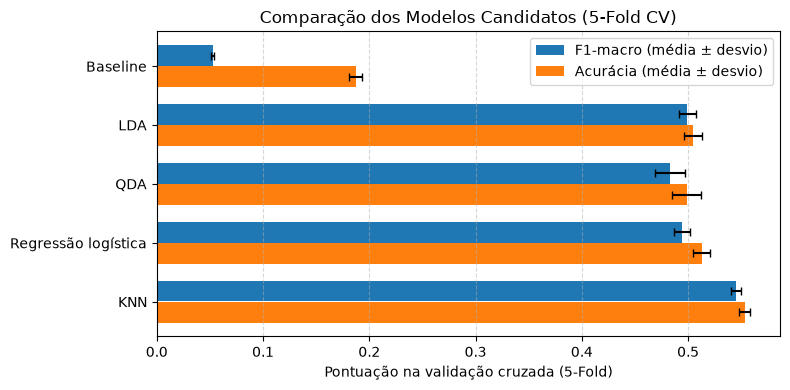

In [110]:
comparison_df = pd.DataFrame.from_dict(cv_best_models, orient="index")
comparison_df = comparison_df.rename(
    columns={
        "mean_macro_f1": "F1-macro val (média)",
        "std_macro_f1": "F1-macro val (desvio)",
        "mean_accuracy": "Acurácia val (média)",
        "std_accuracy": "Acurácia val (desvio)",
    }
)

display(comparison_df.round(4))

# gráfico comparativo do F1-macro e Acurácia nos 5 folds
fig, ax = plt.subplots(figsize=(8, 4))
y_pos = np.arange(len(comparison_df))

ax.barh(
    y_pos - 0.18,
    comparison_df["F1-macro val (média)"],
    xerr=comparison_df["F1-macro val (desvio)"],
    height=0.35,
    label="F1-macro (média ± desvio)",
    capsize=3,
)
ax.barh(
    y_pos + 0.18,
    comparison_df["Acurácia val (média)"],
    xerr=comparison_df["Acurácia val (desvio)"],
    height=0.35,
    label="Acurácia (média ± desvio)",
    capsize=3,
)

ax.set_yticks(y_pos)
ax.set_yticklabels(comparison_df.index)
ax.invert_yaxis()
ax.set_xlabel("Pontuação na validação cruzada (5-Fold)")
ax.set_title("Comparação dos Modelos Candidatos (5-Fold CV)")
ax.legend()
ax.grid(axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

### 7.1 Escolha do modelo final

O modelo escolhido foi o **KNN com $k=35$**.
- **Critério:** Apresentou o melhor desempenho geral na validação cruzada de 5 folds, atingindo **F1-macro de 0,5450 ± 0,0051** e **acurácia de 0,5532 ± 0,0054**.
- **Estabilidade:** Manteve baixo desvio padrão entre as partições.
- **Decisão:** O ganho de cerca de +4,6 pontos percentuais no F1-macro compensa o custo computacional de predição frente aos métodos paramétricos, consolidando-o como o candidato para o conjunto de teste final.

## 8. Avaliação final no conjunto de teste


### 8.1 Treino final

In [ ]:
# ajusta o pré-processamento no conjunto de treino completo e aplica no treino e no teste
final_params = fit_preprocess(train_df)
X_train_full, y_train_full = apply_preprocess(train_df, final_params)
X_test, y_test = apply_preprocess(test_df, final_params)

best_k = best_knn["k"]
final_model = KNN(k=best_k)

start = time.perf_counter()
final_model.fit(X_train_full, y_train_full)
fit_time_test = time.perf_counter() - start

start = time.perf_counter()
y_test_pred = final_model.predict(X_test)
pred_time_test = time.perf_counter() - start

print(f"Modelo final treinado: KNN(k={best_k})")
print(f"Treino completo: {X_train_full.shape} | Teste final: {X_test.shape}")
print(f"Tempo de treino: {fit_time_test:.3f}s | Tempo de previsão no teste: {pred_time_test:.3f}s")

Modelo final treinado: KNN(k=35)
Treino completo: (21335, 24) | Teste final: (5333, 24)
Tempo de treino: 0.000s | Tempo de previsão no teste: 154.693s


### 8.2 Métricas no teste

In [112]:
# métricas por gênero 
prec_test = np.nan_to_num(precision(y_test, y_test_pred, LABELS))
rec_test = np.nan_to_num(recall(y_test, y_test_pred, LABELS))
spec_test = np.nan_to_num(specificity(y_test, y_test_pred, LABELS))
f1_test = np.nan_to_num(f1_score(y_test, y_test_pred, LABELS))

# resumo o teste
test_summary = pd.DataFrame(
    {
        "F1-macro": [float(np.mean(f1_test))],
        "Acurácia": [accuracy(y_test, y_test_pred)],
        "Precisão-macro": [float(np.mean(prec_test))],
        "Recall-macro": [float(np.mean(rec_test))],
        "Especificidade-macro": [float(np.mean(spec_test))],
    },
    index=[f"KNN (k={best_k}) — Conjunto de Teste"],
)
display(test_summary.round(4))

# tabela por gênero musical
per_genre_df = pd.DataFrame(
    {
        "Precisão": prec_test,
        "Recall": rec_test,
        "Especificidade": spec_test,
        "F1-score": f1_test,
        "Nº de faixas (teste)": [int(np.sum(y_test == g)) for g in LABELS],
    },
    index=pd.Index(LABELS, name="Gênero"),
)
display(per_genre_df.round(4))

,F1-macro,Acurácia,Precisão-macro,Recall-macro,Especificidade-macro
KNN (k=35) — Conjunto de Teste,0.5318,0.5397,0.5368,0.5323,0.9078


,Precisão,Recall,Especificidade,F1-score,Nº de faixas (teste)
Gênero,,,,,
edm,0.5640,0.7323,0.8733,0.6372,975
latin,0.4601,0.4347,0.9105,0.4470,796
pop,0.3584,0.3549,0.8846,0.3566,820
r&b,0.5118,0.4393,0.9160,0.4728,890
rap,0.5878,0.5796,0.9063,0.5837,999
rock,0.7387,0.6530,0.9560,0.6932,853


### 8.3 Gráficos

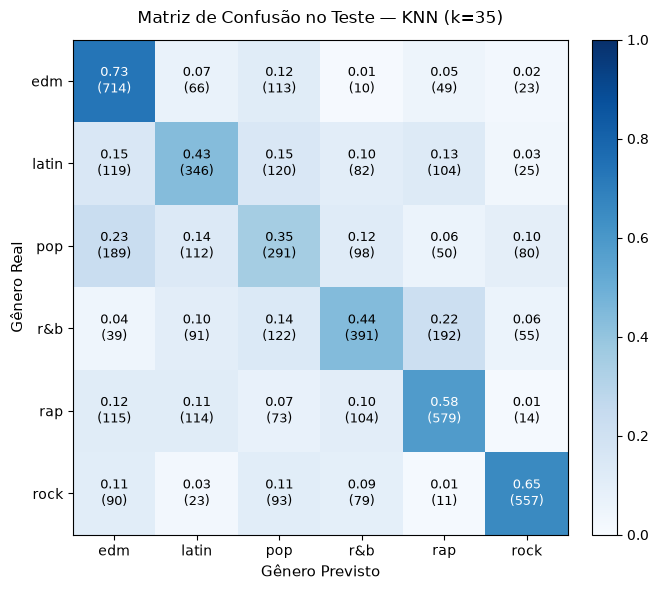

In [113]:
cm = confusion_matrix(y_test, y_test_pred, LABELS)
cm_norm = cm / cm.sum(axis=1, keepdims=True)

plt.figure(figsize=(7, 6))
im = plt.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)

plt.xticks(np.arange(len(LABELS)), LABELS)
plt.yticks(np.arange(len(LABELS)), LABELS)
plt.xlabel("Gênero Previsto", fontsize=11)
plt.ylabel("Gênero Real", fontsize=11)
plt.title(f"Matriz de Confusão no Teste — KNN (k={best_k})", fontsize=12, pad=12)

for i in range(len(LABELS)):
    for j in range(len(LABELS)):
        text_color = "white" if cm_norm[i, j] > 0.5 else "black"
        plt.text(
            j,
            i,
            f"{cm_norm[i, j]:.2f}\n({cm[i, j]})",
            ha="center",
            va="center",
            color=text_color,
            fontsize=9,
        )

plt.colorbar(im, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

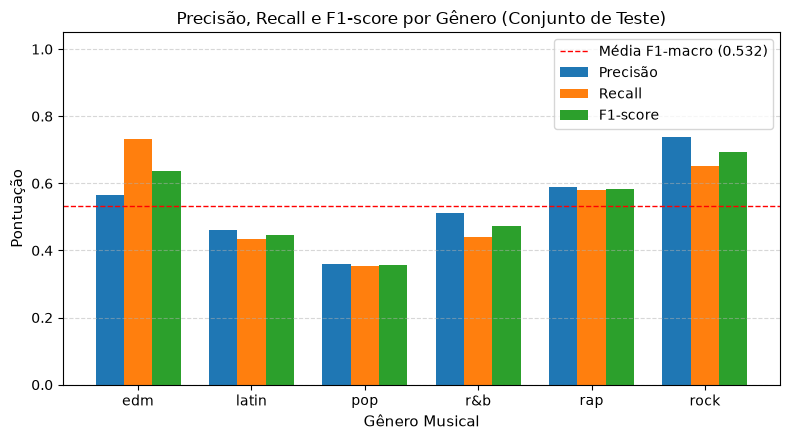

In [114]:
x = np.arange(len(LABELS))
w = 0.25

plt.figure(figsize=(8, 4.5))
plt.bar(x - w, prec_test, width=w, label="Precisão", color="#1f77b4")
plt.bar(x, rec_test, width=w, label="Recall", color="#ff7f0e")
plt.bar(x + w, f1_test, width=w, label="F1-score", color="#2ca02c")

plt.xticks(x, LABELS, fontsize=10)
plt.ylim(0, 1.05)
plt.ylabel("Pontuação", fontsize=11)
plt.xlabel("Gênero Musical", fontsize=11)
plt.title("Precisão, Recall e F1-score por Gênero (Conjunto de Teste)", fontsize=12)
plt.axhline(test_summary["F1-macro"].iloc[0], color="red", linestyle="--", linewidth=1, label=f"Média F1-macro ({test_summary['F1-macro'].iloc[0]:.3f})")

plt.legend(frameon=True)
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

## 9. Conclusão

- **Melhor modelo e desempenho no teste:**
  - O **KNN ($k = 35$)** foi o melhor modelo entre os 5 avaliados.
  - **Resultado no conjunto de teste final (5.333 faixas):**
    - **F1-macro:** **0,5318**.
    - **Acurácia:** **53,97%**.
    - **Especificidade-macro:** **90,78%**.
  - O modelo apresentou uma ótima generalização, com queda de 0,013 de F1 em relação à validação cruzada (0,5450 $\rightarrow$ 0,5318).
  - Destaque para a identificação de **Rock** ($F1 = 0,6932$) e **EDM** ($F1 = 0,6372$), que possuem assinaturas acústicas mais demarcadas.

- **Principais limitações:**
  - **Ruído de rótulo:** Músicas são rotuladas pelo gênero da *playlist*, não da composição. O gênero **Pop** foi o mais difícil de prever ($F1 = 0,3566$) por se sobrepor acusticamente a todos os demais clusters.
  - **Custo computacional de inferência:** O KNN exigiu **$\approx$ 2,6 minutos** para prever apenas o conjunto de teste, pois calcula distâncias ponto a ponto para cada nova observação contra as mais de 21 mil faixas de treino. Para um sistema em produção no Spotify, modelos como **LDA** ou **Regressão Logística** seriam alternativas viáveis por executarem predições instantâneas com perda aceitável de F1 ($\approx 0,49$ a $0,50$).
  - **Atributos puramente acústicos:** A ausência de metadados de texto, como letras das faixas ou áudio bruto limita o teto preditivo teórico no problema multiclasse.